# Synthetic Degree Completion Analysis | 2020–2024

**Public demonstration — all records and findings are fictional.** This notebook reproduces the *analytical structure* of a stakeholder report: summary, degree-by-season findings, completion counts, median completion time, and technical appendix. No institutional dataset, fitted parameters, counts, or internal results are used.

**Research question:** Within each degree category and season, do the population median completion times differ among completion years 2020–2024?

Run the notebook in the same directory as `synthetic_completion_data.csv`. To regenerate the independent sample, run `python generate_synthetic_data.py` first. Statistical results depend on the synthetic random sample and are not claims about any real university.

## 1 · Setup and data integrity

In [ ]:
from pathlib import Path
import itertools
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from IPython.display import display, Markdown

ALPHA = 0.05
SEASONS = ['Spring', 'Summer', 'Fall']
YEARS = list(range(2020, 2025))
DEGREES = ['Masters', 'Research Doctorate']
DATA_PATH = Path('data/synthetic_completion_data.csv')
OUTPUT_CHARTS_DIR = Path('figures')
OUTPUT_CHARTS_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_DIR = Path("results")
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
assert DATA_PATH.exists(), 'Run generate_synthetic_data.py first or place CSV beside notebook.'
df = pd.read_csv(DATA_PATH)
required = {'Completed.Term.Descr', 'Degree.Descr', 'Completed.Time'}
assert required.issubset(df.columns)
df['Completed.Time'] = pd.to_numeric(df['Completed.Time'], errors='coerce')
df[['Season', 'Year']] = df['Completed.Term.Descr'].str.extract(r'^(Spring|Summer|Fall)\s+(20\d{2})$')
df['Year'] = pd.to_numeric(df['Year'], errors='coerce')
df = df.dropna(subset=['Season', 'Year', 'Completed.Time', 'Degree.Descr']).copy()
df = df.loc[df['Year'].isin(YEARS) & (df['Completed.Time'] > 0) & df['Degree.Descr'].isin(DEGREES)]
df['Year'] = df['Year'].astype(int)
assert len(df) > 0
print(f'{len(df):,} synthetic observations | {df["Degree.Descr"].nunique()} degree categories | {df["Completed.Term.Descr"].nunique()} terms')
display(df.head())

1,106 synthetic observations | 2 degree categories | 15 terms


,Completed.Term.Descr,Degree.Descr,Completed.Time,Season,Year
0,Spring 2024,Research Doctorate,3.342,Spring,2024
1,Fall 2023,Masters,3.140,Fall,2023
2,Spring 2024,Masters,2.955,Spring,2024
3,Fall 2020,Masters,1.889,Fall,2020
4,Fall 2022,Masters,1.730,Fall,2022


## 2 · Descriptive statistics and individual term subsets

Each `(Completed.Term.Descr, Degree.Descr)` combination has its own dataframe. The primary tests compare **years within a fixed season and degree**, not seasons against one another.

In [ ]:
term_degree_dfs = {(term, degree): part.copy() for (term, degree), part in df.groupby(['Completed.Term.Descr', 'Degree.Descr'])}
assert len(term_degree_dfs) == 30
summary = (df.groupby(['Degree.Descr','Season','Year'], observed=True)['Completed.Time']
           .agg(N='size', Median='median', Q1=lambda s: s.quantile(.25), Q3=lambda s: s.quantile(.75))
           .reset_index())
summary['IQR'] = summary['Q3'] - summary['Q1']
display(summary.round(2))
summary.to_csv(RESULTS_DIR / 'descriptive_statistics.csv', index=False)

,Degree.Descr,Season,Year,N,Median,Q1,Q3,IQR
0,Masters,Fall,2020,44,2.02,1.61,2.72,1.11
1,Masters,Fall,2021,52,2.38,1.97,3.28,1.30
2,Masters,Fall,2022,47,2.70,2.26,3.34,1.07
3,Masters,Fall,2023,32,2.38,2.02,2.90,0.88
4,Masters,Fall,2024,36,2.49,1.97,3.54,1.57
5,Masters,Spring,2020,52,2.40,1.90,2.86,0.95
6,Masters,Spring,2021,52,2.56,1.81,2.95,1.15
7,Masters,Spring,2022,37,2.28,1.98,3.55,1.57
8,Masters,Spring,2023,56,2.56,1.87,3.06,1.19
9,Masters,Spring,2024,50,2.67,2.09,3.37,1.29


### Distribution plots: five-bin histograms and boxplots

For each of the 30 term-by-degree subsets, create a **five-bin histogram** and a **boxplot** showing the distribution of synthetic completion times. The histogram uses a zero-based count axis and a completion-time axis starting at zero; the boxplot shows median, quartiles, and potential outliers. All figures are saved to `outputs/` to keep the notebook compact. Set `SHOW_DISTRIBUTION_PLOTS = True` to display each figure inline as well.


In [ ]:
SHOW_DISTRIBUTION_PLOTS = False

for (term, degree), part in term_degree_dfs.items():
    values = part['Completed.Time'].dropna().to_numpy()
    slug = f'{degree.lower().replace(" ", "_")}_{term.lower().replace(" ", "_")}'

    # Histogram: exactly five bins
    fig, ax = plt.subplots(figsize=(6, 3.7))
    ax.hist(values, bins=5, edgecolor='white')
    ax.set(xlabel='Completed Time (Years)', ylabel='Number of Completions',
           title=f'{degree} | {term} | Synthetic data')
    ax.set_xlim(left=0)
    ax.set_ylim(bottom=0)
    ax.grid(axis='y', alpha=.18)
    fig.tight_layout()
    fig.savefig(OUTPUT_CHARTS_DIR / f'hist_{slug}.png', dpi=140)
    if SHOW_DISTRIBUTION_PLOTS:
        plt.show()
    else:
        plt.close(fig)

    # Horizontal boxplot: median, IQR, whiskers, and outliers
    fig, ax = plt.subplots(figsize=(6, 2.8))
    ax.boxplot(values, vert=False, widths=0.45, showfliers=True)
    ax.set(xlabel='Completed Time (Years)', title=f'{degree} | {term} | Synthetic data')
    ax.set_yticks([1], ['Completions'])
    ax.set_xlim(left=0)
    ax.grid(axis='x', alpha=.18)
    fig.tight_layout()
    fig.savefig(OUTPUT_CHARTS_DIR / f'box_{slug}.png', dpi=140)
    if SHOW_DISTRIBUTION_PLOTS:
        plt.show()
    else:
        plt.close(fig)

print(f'Saved {len(term_degree_dfs)} histograms and {len(term_degree_dfs)} boxplots in {OUTPUT_CHARTS_DIR}/')


Saved 30 histograms and 30 boxplots in outputs/


## 3 · Omnibus Mood’s median tests

For each degree × season, compare the five annual groups. Null: all five population medians are equal. Alternative: at least one differs. SciPy’s `median_test` uses a chi-square approximation; sparse expected counts are flagged. A nonsignificant test does **not** establish equality.

In [ ]:
omnibus_rows = []
for degree in DEGREES:
    for season in SEASONS:
        sub = df.loc[(df['Degree.Descr'] == degree) & (df['Season'] == season)]
        groups = [sub.loc[sub['Year'] == year, 'Completed.Time'].to_numpy() for year in YEARS]
        if any(len(g) == 0 for g in groups):
            omnibus_rows.append({'Degree': degree, 'Season': season, 'Statistic': np.nan,
                                 'p_value': np.nan, 'Grand_median': np.nan,
                                 'Min_expected': np.nan, 'Result': 'Not testable'})
            continue
        chi2, pval, grand_median, contingency = stats.median_test(*groups, ties='below')
        expected = stats.contingency.expected_freq(contingency)
        omnibus_rows.append({'Degree': degree, 'Season': season, 'Statistic': chi2,
                             'p_value': pval, 'Grand_median': grand_median,
                             'Min_expected': expected.min(),
                             'Result': 'Evidence of difference' if pval < ALPHA else 'Not established'})
omnibus = pd.DataFrame(omnibus_rows)
display(omnibus.round(4))
omnibus.to_csv(RESULTS_DIR / 'omnibus_median_tests.csv', index=False)
if (omnibus['Min_expected'] < 5).any():
    print('CAUTION: Sparse expected counts: chi-square p-values may be unreliable; consider an exact/permutation approach.')

,Degree,Season,Statistic,p_value,Grand_median,Min_expected,Result
0,Masters,Spring,2.7459,0.6012,2.5070,18.4251,Not established
1,Masters,Summer,13.6441,0.0085,3.0725,17.0000,Evidence of difference
2,Masters,Fall,11.2473,0.0239,2.3980,15.9242,Evidence of difference
3,Research Doctorate,Spring,2.2440,0.6910,5.1590,9.0000,Not established
4,Research Doctorate,Summer,11.3705,0.0227,5.6770,10.4295,Evidence of difference
5,Research Doctorate,Fall,4.5403,0.3378,4.6730,8.9371,Not established


## 4 · Pairwise follow-up tests and Holm correction

For each degree-season with significant omnibus evidence, conduct all 10 two-year Mood median comparisons. Holm adjustment controls family-wise error within that degree-season. Pairwise tests use a **separate pooled median for each pair**; pairwise conclusions may differ from omnibus results. Sparse expected cells are flagged, not treated as reliable confirmation.

In [ ]:
pairwise_rows = []
for _, overall in omnibus.iterrows():
    if not (np.isfinite(overall['p_value']) and overall['p_value'] < ALPHA):
        continue
    degree, season = overall['Degree'], overall['Season']
    sub = df.loc[(df['Degree.Descr'] == degree) & (df['Season'] == season)]
    for a, b in itertools.combinations(YEARS, 2):
        x = sub.loc[sub['Year'] == a, 'Completed.Time'].to_numpy()
        y = sub.loc[sub['Year'] == b, 'Completed.Time'].to_numpy()
        stat, pv, _, ct = stats.median_test(x, y, ties='below', correction=False)
        exp_min = stats.contingency.expected_freq(ct).min()
        pairwise_rows.append({'Degree': degree, 'Season': season, 'Year_1': a, 'Year_2': b,
                              'Median_difference_Year2_minus_Year1': np.median(y)-np.median(x),
                              'Statistic': stat, 'p_value': pv, 'Min_expected': exp_min})
pairwise = pd.DataFrame(pairwise_rows)
if not pairwise.empty:
    pairwise['p_Holm'] = np.nan
    for (_, _), idx in pairwise.groupby(['Degree', 'Season']).groups.items():
        idx = list(idx)
        vals = pairwise.loc[idx, 'p_value'].to_numpy()
        order = np.argsort(vals)
        adjusted_sorted = np.maximum.accumulate((len(vals) - np.arange(len(vals))) * vals[order])
        adjusted = np.empty(len(vals))
        adjusted[order] = np.clip(adjusted_sorted, 0, 1)
        pairwise.loc[idx, 'p_Holm'] = adjusted
    pairwise['Significant_after_Holm'] = pairwise['p_Holm'] < ALPHA
    pairwise['Approximation_warning'] = pairwise['Min_expected'] < 5
    display(pairwise.round(4))
else:
    print('No omnibus tests were significant; no post-hoc comparisons were run.')
pairwise.to_csv(RESULTS_DIR / 'pairwise_tests.csv', index=False)

,Degree,Season,Year_1,Year_2,Median_difference_Year2_minus_Year1,Statistic,p_value,Min_expected,p_Holm,Significant_after_Holm,Approximation_warning
0,Masters,Summer,2020,2021,0.4560,2.1778,0.1400,22.5000,0.8401,False,False
1,Masters,Summer,2020,2022,0.8240,9.7872,0.0018,22.5000,0.0176,True,False
2,Masters,Summer,2020,2023,0.8880,9.5918,0.0020,22.5000,0.0176,True,False
3,Masters,Summer,2020,2024,0.9645,7.9795,0.0047,16.7848,0.0378,True,False
4,Masters,Summer,2021,2022,0.3680,3.5234,0.0605,22.5000,0.4236,False,False
5,Masters,Summer,2021,2023,0.4320,2.0889,0.1484,22.5000,0.8401,False,False
6,Masters,Summer,2021,2024,0.5085,1.0136,0.3140,16.7848,1.0000,False,False
7,Masters,Summer,2022,2023,0.0640,0.0417,0.8382,23.5000,1.0000,False,False
8,Masters,Summer,2022,2024,0.1405,0.9903,0.3197,16.7901,1.0000,False,False
9,Masters,Summer,2023,2024,0.0765,0.9689,0.3250,16.7952,1.0000,False,False


## 5 · Stakeholder summary

The narrative below is computed from the fictional dataset. **Not established** means there was insufficient evidence of a difference, not that medians are equal.

In [6]:
for degree in DEGREES:
    display(Markdown(f'### {degree}'))
    for season in SEASONS:
        row = omnibus.loc[(omnibus['Degree'] == degree) & (omnibus['Season'] == season)].iloc[0]
        start = summary.query('`Degree.Descr` == @degree and Season == @season and Year == 2020')['Median'].iloc[0]
        end = summary.query('`Degree.Descr` == @degree and Season == @season and Year == 2024')['Median'].iloc[0]
        msg = (f'**{season}:** Synthetic median completion time was {start:.2f} years in 2020 '
               f'and {end:.2f} years in 2024. Omnibus result: **{row["Result"]}** '
               f'(p = {row["p_value"]:.3g}).')
        if row['Min_expected'] < 5:
            msg += ' Small expected counts limit the reliability of this approximation.'
        display(Markdown(msg))
        if not pairwise.empty:
            sig = pairwise.loc[(pairwise['Degree'] == degree) & (pairwise['Season'] == season) & pairwise['Significant_after_Holm']]
            if not sig.empty:
                pairs = ', '.join(f'{int(r.Year_1)}–{int(r.Year_2)}' for r in sig.itertuples())
                display(Markdown(f'Holm-adjusted pairwise evidence: **{pairs}**.'))

### Masters

**Spring:** Synthetic median completion time was 2.40 years in 2020 and 2.67 years in 2024. Omnibus result: **Not established** (p = 0.601).

**Summer:** Synthetic median completion time was 2.50 years in 2020 and 3.46 years in 2024. Omnibus result: **Evidence of difference** (p = 0.00852).

Holm-adjusted pairwise evidence: **2020–2022, 2020–2023, 2020–2024**.

**Fall:** Synthetic median completion time was 2.02 years in 2020 and 2.49 years in 2024. Omnibus result: **Evidence of difference** (p = 0.0239).

...

### Research Doctorate

**Spring:** Synthetic median completion time was 5.64 years in 2020 and 5.15 years in 2024. Omnibus result: **Not established** (p = 0.691).

**Summer:** Synthetic median completion time was 5.00 years in 2020 and 6.64 years in 2024. Omnibus result: **Evidence of difference** (p = 0.0227).

Holm-adjusted pairwise evidence: **2020–2024**.

**Fall:** Synthetic median completion time was 5.27 years in 2020 and 5.40 years in 2024. Omnibus result: **Not established** (p = 0.338).

## 6 · Stakeholder charts

Each degree-season section has paired trend charts with zero-based vertical axes and labeled values. These are descriptive connected-line plots, **not fitted regression trendlines**. The horizontal axis begins at 2020 rather than zero because it represents calendar years.

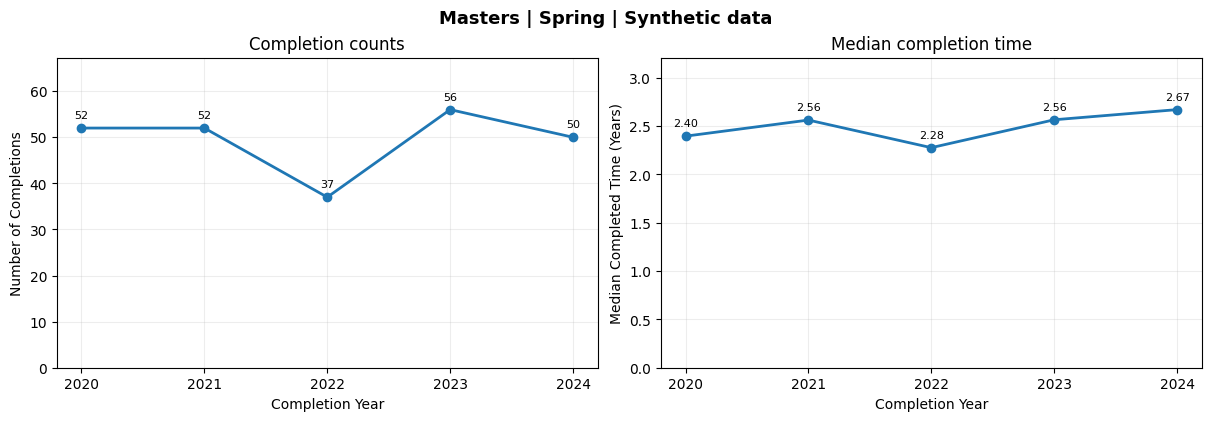

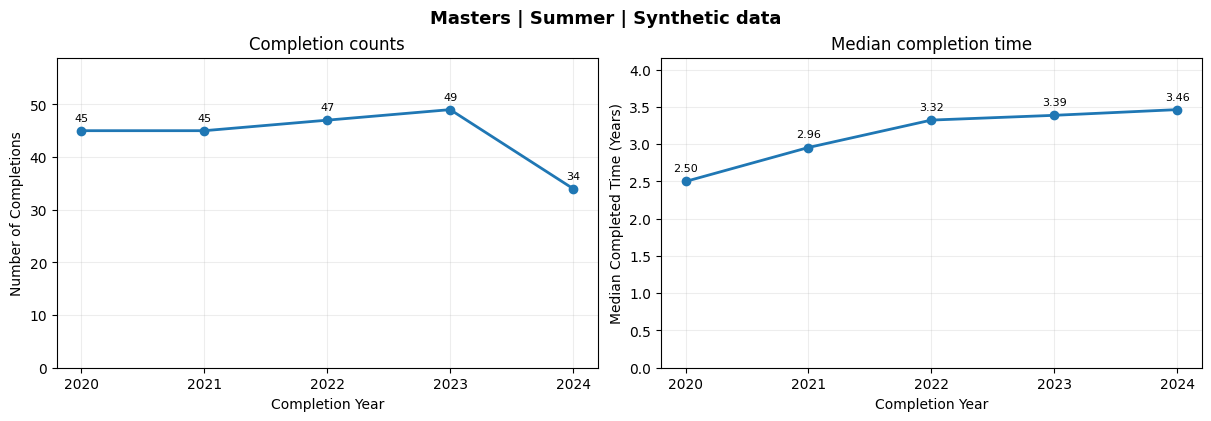

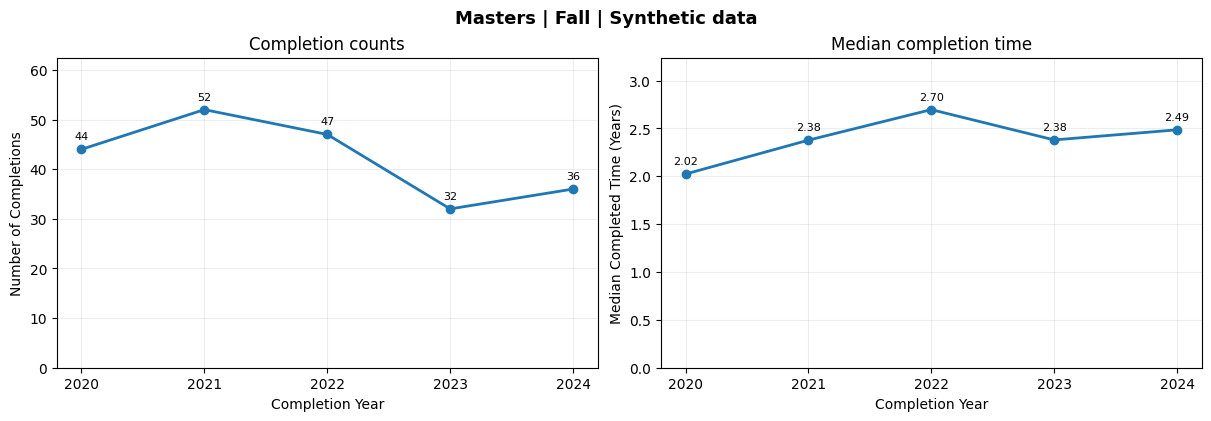

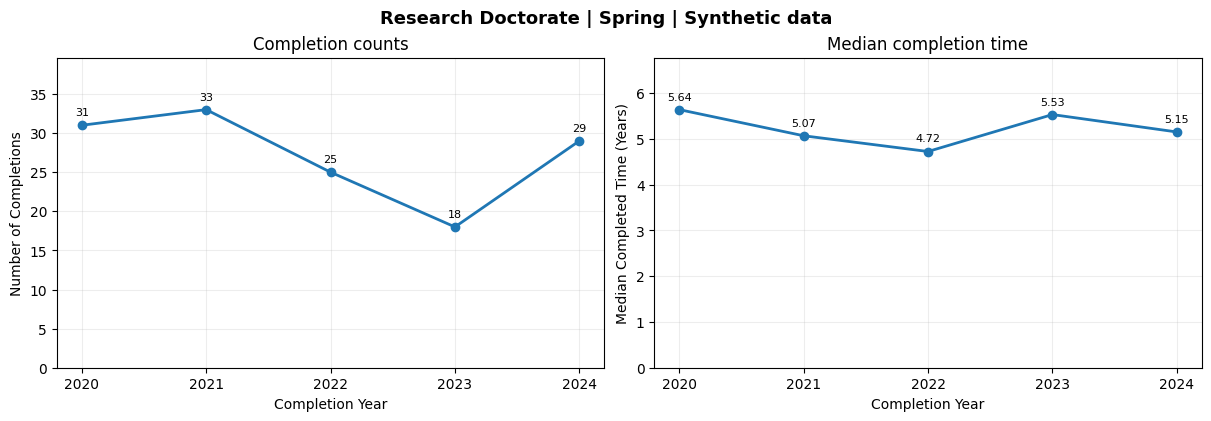

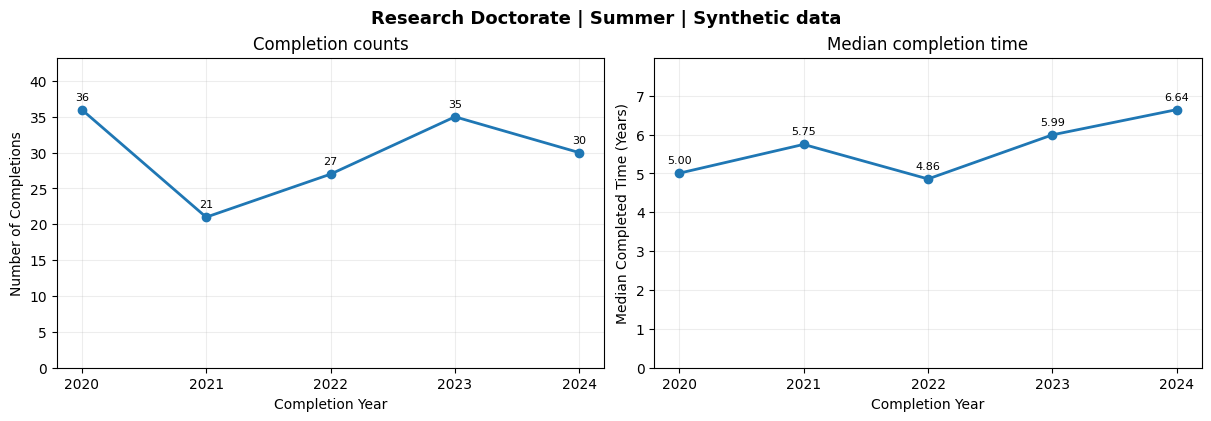

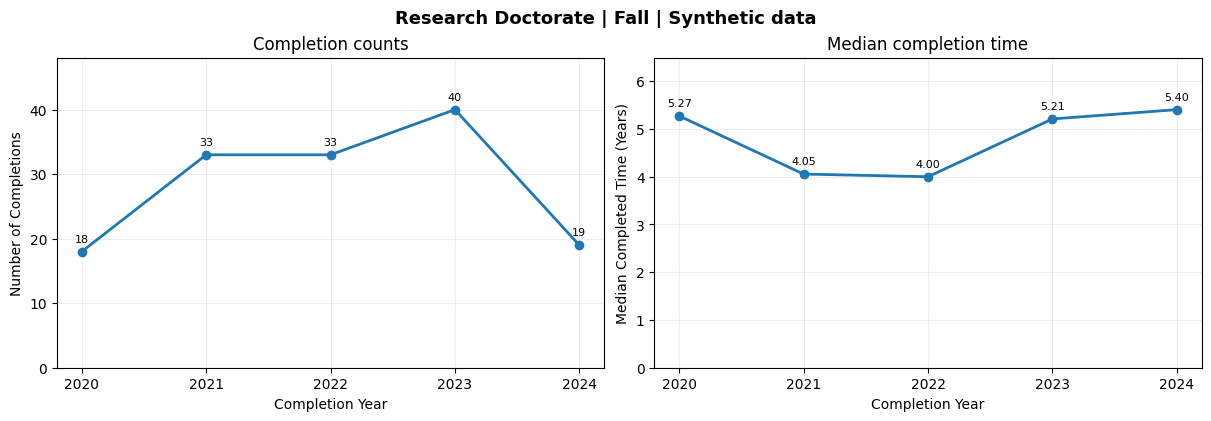

In [ ]:
def trend_charts(degree, season):
    s = summary.loc[(summary['Degree.Descr'] == degree) & (summary['Season'] == season)].sort_values('Year')
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.1), constrained_layout=True)
    for ax, col, ylabel, title in [
        (axes[0], 'N', 'Number of Completions', 'Completion counts'),
        (axes[1], 'Median', 'Median Completed Time (Years)', 'Median completion time')]:
        ax.plot(s['Year'], s[col], marker='o', linewidth=2)
        ax.set(xlabel='Completion Year', ylabel=ylabel, title=title)
        ax.set_xlim(2019.8, 2024.2)
        max_value = s[col].max()
        ax.set_ylim(bottom=0, top=max_value * 1.20 if max_value > 0 else 1)
        ax.set_xticks(YEARS)
        ax.grid(alpha=.22)
        for year, value in zip(s['Year'], s[col]):
            ax.annotate(f'{value:.0f}' if col == 'N' else f'{value:.2f}',
                        (year, value), xytext=(0, 7), textcoords='offset points',
                        ha='center', fontsize=8)
    fig.suptitle(f'{degree} | {season} | Synthetic data', fontsize=13, fontweight='bold')
    filename = f'{degree.lower().replace(" ", "_")}_{season.lower()}_trends.png'
    fig.savefig(OUTPUT_CHARTS_DIR / filename, dpi=170, bbox_inches='tight')
    plt.show()

for degree in DEGREES:
    for season in SEASONS:
        trend_charts(degree, season)

## 7 · Technical appendix: definitions, assumptions, limitations

**Completed time:** Fictional positive duration, in years. No actual student dates or records are used. **Completion count:** Number of synthetic observations in a term-degree group. **Median:** Middle observed completion time. **IQR:** 75th percentile minus 25th percentile. **Degree:** Fictional category. **Season/year:** Completion term label, not enrollment cohort.

**Testing:** The six omnibus Mood median tests each compare five independent year groups within a degree-season, using α = .05. Pairwise tests are conducted only following a significant omnibus result, with Holm correction within each family of ten comparisons. Because six omnibus tests are conducted, their p-values are not adjusted across degree-season families; conclusions should be viewed as exploratory. Chi-square approximations can be unreliable for sparse cells; the notebook flags them.

**Uncertainty:** IQR is reported as a descriptive variability measure. Formal confidence intervals are not provided in this demonstration; they should be added with a validated small-sample method if required for inference.

**Scope:** The study compares completion-year groups, not individual students over time; it cannot infer causal effects of COVID, cohort characteristics, or institutional policy. A nonsignificant test is not evidence of equivalence. Counts are descriptive; no formal count-trend inference is claimed. The example parameters and resulting findings are wholly fictional.

**Privacy:** The public dataset was generated from independently chosen distributional assumptions and a fixed random seed. It does not read or fit to an internal spreadsheet. Do not copy outputs, metadata, or identifying details from private notebooks into this project.

## 8 · Export and next steps

Tables and PNGs are written to `outputs/`. For a polished stakeholder PDF, use the generated summary and paired trend charts as the main section and put the detailed tests, histograms, boxplots, and definitions in an appendix. Always verify statistical conclusions and assumptions before publication.